# Secado de leña de eucalipto en Talca: modelo 2D transiente de difusión de humedad
**IIQ2003 – Fenómenos de Transporte, 2026-2** · Proyecto semestral, Entrega 2

Modelo de difusión de humedad en un trozo cilíndrico (coordenadas *r*, *z*), con simetría angular y respecto del plano medio:

$$\frac{\partial M}{\partial t}=D_{ef}\left(\frac{\partial^2 M}{\partial r^2}+\frac1r\frac{\partial M}{\partial r}+\frac{\partial^2 M}{\partial z^2}\right),\quad 0<r<R,\;0<z<L/2$$

Condiciones: $M(r,z,0)=M_0$; $\partial_r M|_{r=0}=0$; $\partial_z M|_{z=L/2}=0$; $-D_{ef}\partial_r M|_{r=R}=h_m(M_{sup}-M_{eq})$; $D_{ef}\partial_z M|_{z=0}=h_m(M_{sup}-M_{eq})$.

**Objetivo:** tiempo $t^*$ para que la humedad promedio llegue a $M=0{,}25$ kg/kg (base seca, NCh 2907).

**Método numérico (como en el curso, Módulo 4):** FTCS (diferencias hacia adelante en el tiempo y centradas en el espacio) sobre una malla de nodos, con matriz $A$, condiciones de borde de segundo orden y criterio de Fourier para el paso de tiempo. Como verificación cruzada se usa además un esquema de volúmenes finitos con Euler implícito. Las funciones están en `modelo_secado.py`. Unidades SI.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import modelo_secado as ms

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
DIA = 86400.0   # [s/día]

## 1. Parámetros
**Los valores marcados con ⚠ son supuestos que el grupo debe verificar con una fuente antes de la entrega final.**

In [2]:
# --- Geometría del trozo (⚠ supuesto: leña típica; confirmar largo comercial) ---
R = 0.05          # radio del trozo [m]            (diámetro 10 cm)
L = 0.30          # largo del trozo [m]

# --- Madera: Eucalyptus globulus ---
D_ef = 3.0e-10    # difusividad efectiva [m2/s]. Rango 1,5-4,5e-10 medido en E. nitens (Biobío)
M0 = 0.80         # humedad inicial, base seca [kg/kg]  ⚠ confirmar para E. globulus verde
rho_s = 550.0     # densidad básica madera seca [kg/m3] ⚠ confirmar (para h_m y balances de masa)

# --- Aire (T y HR constantes por escenario) ---
# Verano: normal de enero Talca, T media = (30,9 + 12,1)/2. ⚠ HR de verano es supuesto (completar con boletín U. Talca)
# Invierno: normal de junio, T media = (13,3 + 5,1)/2; HR = promedio de 97,4 % (08:00) y 71,4 % (14:00) de junio 2025
ESCENARIOS = {
    "Verano (enero)":  dict(T=(30.9 + 12.1) / 2, HR=0.55),
    "Invierno (junio)": dict(T=(13.3 + 5.1) / 2, HR=0.844),
}
u_viento = 1.0    # velocidad del viento [m/s] ⚠ supuesto

# --- Objetivo ---
M_obj = 0.25      # humedad objetivo [kg/kg, base seca]

# --- Parámetros numéricos (se justifican en la sección 3) ---
Nr, Nz = 20, 60   # intervalos en r y en z (mitad del largo); nodos = N + 1
t_max = 600 * DIA # tiempo máximo simulado [s]

# Paso de tiempo FTCS: 90 % del máximo estable (criterio de Fourier)
dr, dz = R / Nr, (L / 2) / Nz
dt = 0.9 * ms.dt_estable(D_ef, dr, dz)
print(f"dr = {dr*1000:.2f} mm, dz = {dz*1000:.2f} mm")
print(f"dt máximo estable = {ms.dt_estable(D_ef, dr, dz):.0f} s ; dt usado = {dt:.0f} s ; Fo = D·dt/dr² = {D_ef*dt/dr**2:.3f}")

dr = 2.50 mm, dz = 2.50 mm
dt máximo estable = 3472 s ; dt usado = 3125 s ; Fo = D·dt/dr² = 0.150


In [3]:
for nombre, e in ESCENARIOS.items():
    e["M_eq"] = ms.humedad_equilibrio(e["T"], e["HR"])
    e["h_m"] = ms.h_masa_efectivo(e["T"], e["HR"], u_viento, 2 * R, rho_s)
    e["Bi"] = e["h_m"] * R / D_ef
    print(f"{nombre:17s} T={e['T']:5.1f} °C  HR={e['HR']*100:4.1f} %  "
          f"M_eq={e['M_eq']*100:5.1f} %  h_m={e['h_m']:.2e} m/s  Bi_m={e['Bi']:.0f}")

Verano (enero)    T= 21.5 °C  HR=55.0 %  M_eq= 10.0 %  h_m=2.01e-06 m/s  Bi_m=335
Invierno (junio)  T=  9.2 °C  HR=84.4 %  M_eq= 18.1 %  h_m=3.74e-07 m/s  Bi_m=62


`h_m` se estima con una correlación de Sherwood (Churchill–Bernstein) y se convierte a base $M$ usando la pendiente de la isoterma. Con $Bi_m\gg1$ la resistencia del aire es pequeña frente a la difusión interna, pero no nula: en la sensibilidad (sección 6) reducir $h_m$ diez veces alarga $t^*$ cerca de un 10 %.

## 2. Método FTCS
En cada nodo interior $(i,j)$:

$$\frac{M_{i,j}^{n+1}-M_{i,j}^{n}}{\Delta t}=D_{ef}\left[\frac{M_{i+1,j}-2M_{i,j}+M_{i-1,j}}{\Delta r^2}+\frac{M_{i+1,j}-M_{i-1,j}}{2r_i\Delta r}+\frac{M_{i,j+1}-2M_{i,j}+M_{i,j-1}}{\Delta z^2}\right]^n$$

- **Eje ($r=0$):** el término $\frac1r\partial_rM$ vale $\partial_r^2M$ por simetría, así que el término radial queda $4D(M_1-M_0)/\Delta r^2$.
- **Bordes ($r=R$, $z=0$):** la condición Robin se resuelve para el nodo de borde con derivada de segundo orden, igual que en el curso (corrección del borde después de cada paso).
- **Plano medio ($z=L/2$):** $M_{N}=(4M_{N-1}-M_{N-2})/3$ (Neumann de segundo orden, como en el Módulo 4).
- **Estabilidad:** $\Delta t\le 1/(4D/\Delta r^2+2D/\Delta z^2)$. Con $D_{ef}\sim10^{-10}$ m²/s este límite es del orden de horas, así que FTCS es viable.
- La matriz $A$ (dispersa) tiene el patrón de la figura siguiente.

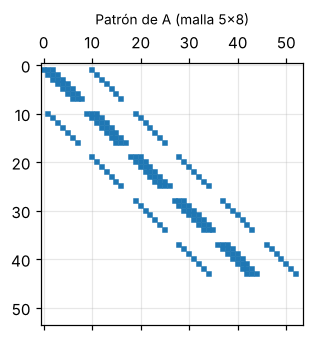

In [4]:
# Patrón de la matriz A (como la gráfica spy del curso) en una malla chica
import scipy.sparse as sp
fig, ax = plt.subplots(figsize=(3.2, 3.2))
Nr_d, Nz_d, N_d = 5, 8, 6 * 9
A_demo = np.zeros((N_d, N_d))
for i in range(5):
    for j in range(1, 8):
        k = i * 9 + j
        A_demo[k, k] = 1
        A_demo[k, k + 1] = A_demo[k, k - 1] = 1
        if i > 0: A_demo[k, k - 9] = 1
        A_demo[k, k + 9] = 1
ax.spy(A_demo, markersize=3); ax.set_title("Patrón de A (malla 5×8)", fontsize=9)
plt.tight_layout(); plt.savefig("figures/matriz_A.png"); plt.show()

## 3. Validación contra solución analítica
Para $D_{ef}$ constante, $M_0$ uniforme y borde convectivo existe solución exacta: producto de la solución del cilindro infinito y de una placa de semiespesor $L/2$. Se compara FTCS, el esquema implícito de verificación y la analítica (humedad promedio, verano).

t* analítico          = 16.97 días
t* FTCS               = 16.92 días  (diferencia 0.33 %)
t* implícito (verif.) = 17.03 días  (diferencia 0.31 %)
Error máx. FTCS en M_prom (M_prom < 0,5) = 0.00180 kg/kg


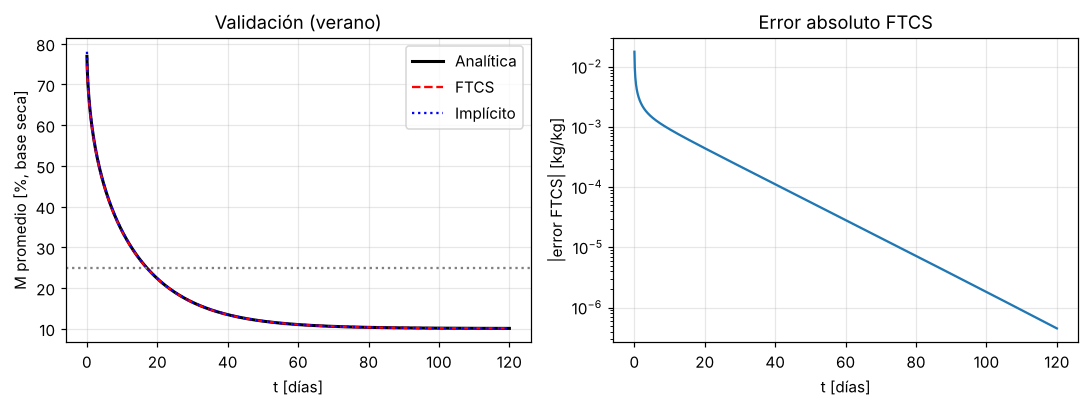

In [5]:
e = ESCENARIOS["Verano (enero)"]
res = ms.resolver_ftcs(R, L, D_ef, e["h_m"], M0, e["M_eq"], Nr, Nz, dt, 120 * DIA, rho_s=rho_s)
imp = ms.resolver(R, L, D_ef, e["h_m"], M0, e["M_eq"], Nr, Nz, 3600.0, 120 * DIA)  # verificación cruzada
t = res["t"][1:]
M_ana = ms.analitica_M_prom(t, R, L, D_ef, e["h_m"], M0, e["M_eq"])
err = np.abs(res["M_prom"][1:] - M_ana)
t_ana = np.interp(M_obj, M_ana[::-1], t[::-1])

print(f"t* analítico          = {t_ana/DIA:.2f} días")
print(f"t* FTCS               = {res['t_prom']/DIA:.2f} días  (diferencia {abs(res['t_prom']-t_ana)/t_ana*100:.2f} %)")
print(f"t* implícito (verif.) = {imp['t_prom']/DIA:.2f} días  (diferencia {abs(imp['t_prom']-t_ana)/t_ana*100:.2f} %)")
print(f"Error máx. FTCS en M_prom (M_prom < 0,5) = {err[res['M_prom'][1:] < 0.5].max():.5f} kg/kg")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].plot(t / DIA, M_ana * 100, "k-", lw=2, label="Analítica")
ax[0].plot(t / DIA, res["M_prom"][1:] * 100, "r--", lw=1.5, label="FTCS")
ax[0].plot(imp["t"][1:] / DIA, imp["M_prom"][1:] * 100, "b:", lw=1.5, label="Implícito")
ax[0].axhline(25, color="gray", ls=":"); ax[0].set(xlabel="t [días]", ylabel="M promedio [%, base seca]", title="Validación (verano)")
ax[0].legend()
ax[1].semilogy(t / DIA, err); ax[1].set(xlabel="t [días]", ylabel="|error FTCS| [kg/kg]", title="Error absoluto FTCS")
plt.tight_layout(); plt.savefig("figures/validacion.png"); plt.show()

## 4. Independencia de grilla
Se refina la malla con celdas cuadradas ($\Delta r=\Delta z$, $N_z=3N_r$). En FTCS el paso de tiempo está atado a la malla (90 % del límite estable), así que se refina junto con ella. Se compara $t^*$ y, de paso, el cierre del balance de masa (sección 5).

  Nr   Nz  dr[mm]   dt[s]  t*_prom[d]  t*_centro[d]  dif vs fina[%]  cierre balance[%]
   5   15   10.00   50000      16.062        33.536            5.29              18.42
  10   30    5.00   12500      16.747        33.713            1.25               8.51
  20   60    2.50    3125      16.916        33.756            0.25               4.03
  40  120    1.25     781      16.958        33.766            0.00               1.87


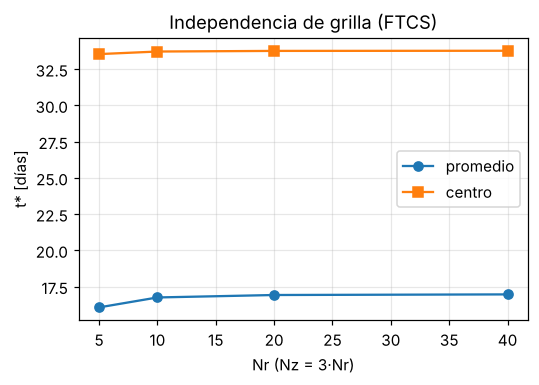

In [6]:
e = ESCENARIOS["Verano (enero)"]
filas = []
for n in [5, 10, 20, 40]:
    dt_n = 0.9 * ms.dt_estable(D_ef, R / n, R / n)
    r_ = ms.resolver_ftcs(R, L, D_ef, e["h_m"], M0, e["M_eq"], n, 3 * n, dt_n, 150 * DIA, rho_s=rho_s)
    perdida = r_["m_agua"][0] - r_["m_agua"][-1]
    integral = np.trapezoid(r_["Q"], r_["t"])
    filas.append((n, 3 * n, R / n * 1000, dt_n, r_["t_prom"] / DIA, r_["t_centro"] / DIA, abs(perdida - integral) / perdida * 100))
ref = filas[-1][4]
print(f"{'Nr':>4} {'Nz':>4} {'dr[mm]':>7} {'dt[s]':>7} {'t*_prom[d]':>11} {'t*_centro[d]':>13} {'dif vs fina[%]':>15} {'cierre balance[%]':>18}")
for n, nz, dr_, dt_, tp, tc, cb in filas:
    print(f"{n:4d} {nz:4d} {dr_:7.2f} {dt_:7.0f} {tp:11.3f} {tc:13.3f} {abs(tp-ref)/ref*100:15.2f} {cb:18.2f}")

fig, ax = plt.subplots(figsize=(5, 3.6))
ax.plot([f[0] for f in filas], [f[4] for f in filas], "o-", label="promedio")
ax.plot([f[0] for f in filas], [f[5] for f in filas], "s-", label="centro")
ax.set(xlabel="Nr (Nz = 3·Nr)", ylabel="t* [días]", title="Independencia de grilla (FTCS)"); ax.legend()
plt.tight_layout(); plt.savefig("figures/grilla.png"); plt.show()

**Elección:** $N_r=20$, $N_z=60$. El criterio de aceptación (por ejemplo, diferencia < 1 % respecto de la malla más fina) lo fija el grupo y debe declararse en el informe.

## 5. Resultados: verano vs. invierno

Verano (enero)    M_eq = 10.0 %  t*(promedio) = 17 días   t*(centro) = 34 días


Invierno (junio)  M_eq = 18.1 %  t*(promedio) = 28 días   t*(centro) = 46 días


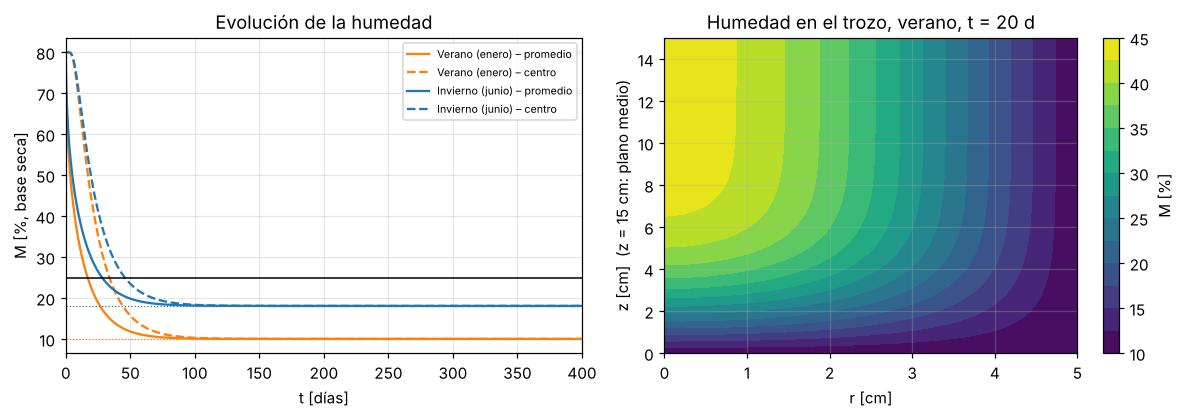

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.9))
resumen = {}
for (nombre, e), col in zip(ESCENARIOS.items(), ["tab:orange", "tab:blue"]):
    r = ms.resolver_ftcs(R, L, D_ef, e["h_m"], M0, e["M_eq"], Nr, Nz, dt, t_max, rho_s=rho_s,
                         guardar_cada=int(10 * DIA / dt))
    resumen[nombre] = r
    ax[0].plot(r["t"] / DIA, r["M_prom"] * 100, color=col, label=f"{nombre} – promedio")
    ax[0].plot(r["t"] / DIA, r["M_centro"] * 100, color=col, ls="--", label=f"{nombre} – centro")
    ax[0].axhline(e["M_eq"] * 100, color=col, ls=":", lw=0.8)
    f = lambda x: "no se alcanza" if np.isnan(x) else f"{x/DIA:.0f} días"
    print(f"{nombre:17s} M_eq = {e['M_eq']*100:.1f} %  t*(promedio) = {f(r['t_prom'])}   t*(centro) = {f(r['t_centro'])}")
ax[0].axhline(25, color="k", ls="-", lw=1); ax[0].set(xlim=(0, 400), xlabel="t [días]", ylabel="M [%, base seca]", title="Evolución de la humedad")
ax[0].legend(fontsize=7)

# Campo de humedad en el trozo, verano, 20 días
r = resumen["Verano (enero)"]
k = sorted(r["snaps"])[1]
RR, ZZ = np.meshgrid(r["rc"] * 100, r["zc"] * 100, indexing="ij")
cs = ax[1].contourf(RR, ZZ, r["snaps"][k] * 100, 15, cmap="viridis")
plt.colorbar(cs, ax=ax[1], label="M [%]"); ax[1].set(xlabel="r [cm]", ylabel="z [cm]  (z = 15 cm: plano medio)", title=f"Humedad en el trozo, verano, t = {k/DIA:.0f} d")
plt.tight_layout(); plt.savefig("figures/resultados.png"); plt.show()

### Cantidades de interés ingenieril y balance macroscópico de agua
Como en la clase de cantidades ingenieriles (Módulo 4), se calculan el caudal de agua perdida por la superficie (flujo con derivada de segundo orden en el borde) y la masa de agua que queda en el trozo, y se verifica el balance:
$$m_{agua}(0)-m_{agua}(t)=\int_0^t \dot m_{perdida}\,dt'$$
Las cantidades son para un trozo completo.

Masa seca del trozo: 1.30 kg ; agua inicial: 1.04 kg
Agua a evaporar hasta M = 25 %: 0.71 kg por trozo
Cierre del balance a t = 60 d: 4.08 %


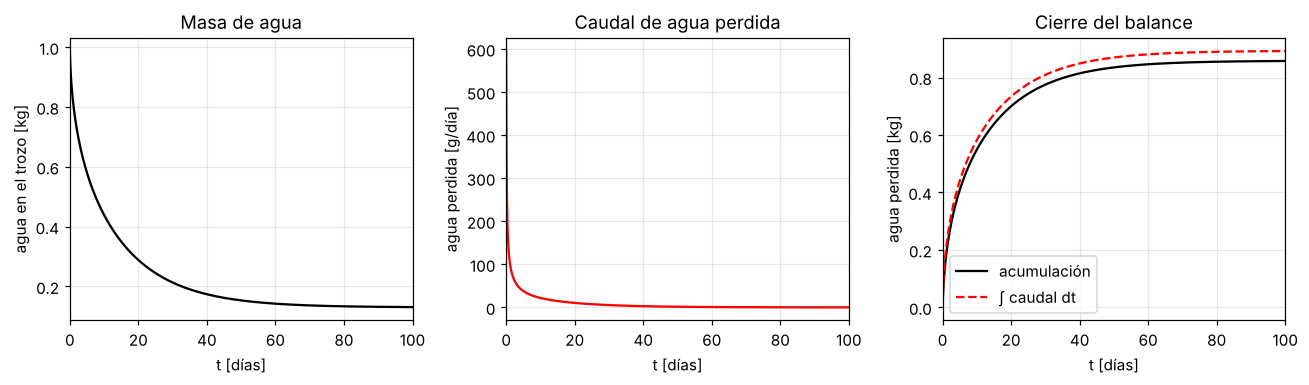

In [8]:
r = resumen["Verano (enero)"]
e = ESCENARIOS["Verano (enero)"]
t = r["t"]
perdida = r["m_agua"][0] - r["m_agua"]
integral = np.concatenate([[0], np.cumsum(0.5 * (r["Q"][1:] + r["Q"][:-1]) * np.diff(t))])

masa_seca = rho_s * np.pi * R**2 * L
print(f"Masa seca del trozo: {masa_seca:.2f} kg ; agua inicial: {masa_seca*M0:.2f} kg")
print(f"Agua a evaporar hasta M = 25 %: {masa_seca*(M0-M_obj):.2f} kg por trozo")
print(f"Cierre del balance a t = 60 d: {abs(perdida[int(60*DIA/dt)]-integral[int(60*DIA/dt)])/perdida[int(60*DIA/dt)]*100:.2f} %")

fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
ax[0].plot(t / DIA, r["m_agua"], "k"); ax[0].set(xlim=(0, 100), xlabel="t [días]", ylabel="agua en el trozo [kg]", title="Masa de agua")
ax[1].plot(t / DIA, r["Q"] * DIA * 1000, "r"); ax[1].set(xlim=(0, 100), xlabel="t [días]", ylabel="agua perdida [g/día]", title="Caudal de agua perdida")
ax[2].plot(t / DIA, perdida, "k", label="acumulación"); ax[2].plot(t / DIA, integral, "r--", label="∫ caudal dt")
ax[2].set(xlim=(0, 100), xlabel="t [días]", ylabel="agua perdida [kg]", title="Cierre del balance"); ax[2].legend()
plt.tight_layout(); plt.savefig("figures/balance.png"); plt.show()

## 6. Sensibilidad
$D_{ef}$ es el parámetro más incierto (rango medido 1,5–4,5×10⁻¹⁰ m²/s). También se varía el diámetro del trozo y $h_m$.

In [9]:
e = ESCENARIOS["Verano (enero)"]
casos = [("D_ef = 1,5e-10", dict(D=1.5e-10)), ("D_ef = 3,0e-10 (base)", dict(D=3.0e-10)),
         ("D_ef = 4,5e-10", dict(D=4.5e-10)),
         ("Diámetro 6 cm (R=3 cm)", dict(R_=0.03)), ("Diámetro 14 cm (R=7 cm)", dict(R_=0.07)),
         ("h_m x 0,1", dict(hf=0.1)), ("h_m x 10", dict(hf=10.0))]
print(f"{'Caso':26s} {'t*_prom [d]':>12} {'t*_centro [d]':>14}")
for nombre, p in casos:
    R_, D_ = p.get("R_", R), p.get("D", D_ef)
    nr = Nr
    nz = 3 * nr if "R_" in p else Nz
    dt_ = 0.9 * ms.dt_estable(D_, R_ / nr, (L / 2) / nz)
    r = ms.resolver_ftcs(R_, L, D_, e["h_m"] * p.get("hf", 1.0), M0, e["M_eq"], nr, nz, dt_, 600 * DIA, rho_s=rho_s)
    print(f"{nombre:26s} {r['t_prom']/DIA:12.1f} {r['t_centro']/DIA:14.1f}")

Caso                        t*_prom [d]  t*_centro [d]


D_ef = 1,5e-10                     33.6           67.3


D_ef = 3,0e-10 (base)              16.9           33.8


D_ef = 4,5e-10                     11.3           22.6


Diámetro 6 cm (R=3 cm)              6.5           12.2


Diámetro 14 cm (R=7 cm)            30.9           65.4


h_m x 0,1                          18.7           35.6


h_m x 10                           16.7           33.6


## 7. Conclusiones
Completar con los números obtenidos arriba:
- Tiempo de secado hasta 25 % en verano vs. invierno, y qué implica para planificar el secado antes del invierno.
- Si en invierno el aire permite o no llegar al 25 % ($M_{eq}$ vs. 25 %).
- Qué tanto cambia $t^*$ con $D_{ef}$ y con el diámetro (sensibilidad).
- Cierre del balance de agua y qué tan bien lo representa la malla elegida.
- Limitaciones: $D_{ef}$ constante e isótropo, aire a T y HR constantes, sin radiación ni lluvia, $\rho_s$ y propiedades homogéneas.
